# UK Online Retail – Sales & Customer Analysis

**Business question:** where does this UK online gift retailer's revenue come from, who are its most valuable customers, and where should it focus to grow?

**Data:** [UCI Online Retail dataset](https://archive.ics.uci.edu/dataset/352/online+retail): 541,909 real transactions from a UK-based online retailer, 1 Dec 2010 – 9 Dec 2011 (licence CC BY 4.0).

**Approach:** clean the data and document every rule → KPIs → revenue trends → markets and products → customer segmentation (RFM) → cohort retention → SQL cross-checks → recommendations.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
from IPython.display import Image, display

import analysis as a
import charts
from clean import clean, load_raw, quality_report_markdown, with_customers
from sql_analysis import run_all

pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load and clean the data
Each cleaning rule is a separate step, and the rows it removes are counted.

In [2]:
raw = load_raw("../data/online_retail.csv.gz")
print(f"Raw data: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
raw.head()

Raw data: 541,909 rows × 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


In [3]:
sales, cancellations, report = clean(raw)
customers = with_customers(sales)
pd.DataFrame(report, columns=["Step", "Rows removed", "Rows remaining"])

,Step,Rows removed,Rows remaining
0,Raw rows loaded,0,541909
1,Exact duplicate rows,5268,536641
2,Cancelled invoices (InvoiceNo starts with 'C'),9251,527390
3,Zero or negative quantity (returns/adjustments),1336,526054
4,Sales reversed by an exact-match cancellation,2860,523194
5,"Zero or negative unit price (free items, bad debt)",1176,522018
6,"Non-product codes (postage, fees, samples)",2286,519732


In [4]:
print(f"Missing CustomerID in raw data: {raw['CustomerID'].isna().mean():.1%} of rows")
print(f"Clean sales rows: {len(sales):,} | rows with a customer: {len(customers):,}")

Missing CustomerID in raw data: 24.9% of rows
Clean sales rows: 519,732 | rows with a customer: 388,345


**Key cleaning decisions**
- **Cancellations** (invoices starting with `C`) are kept in a separate table for analysis, not mixed into sales.
- **Sales reversed by a matching cancellation** are removed. Without this, two orders of 80,995 and 74,215 units that were cancelled within minutes would wrongly appear as the top products.
- Rows with a **missing CustomerID** (about 25%) stay in the revenue and product analysis but are excluded from customer analysis.

## 2. Headline KPIs

In [5]:
k = a.kpis(sales, cancellations)
pd.Series(k, name="value").to_frame()

,value
total_revenue,"9,823,459.37"
revenue_dec10_to_nov11,"9,378,325.77"
orders,"19,648.00"
customers,"4,324.00"
products,"3,902.00"
countries,38.00
average_order_value,499.97
uk_revenue_share,0.85
repeat_customer_rate,0.65
cancelled_invoice_rate,0.16


## 3. Revenue trend

In [6]:
monthly = a.monthly_revenue(sales)
monthly

,revenue,orders,customers,avg_order_value,mom_growth
InvoiceMonth,,,,,
2010-12,"766,924.53",1542,883,497.36,NaN
2011-01,"564,732.93",1073,737,526.31,-0.26
2011-02,"504,714.91",1088,756,463.89,-0.11
2011-03,"682,306.56",1431,970,476.80,0.35
2011-04,"509,523.35",1225,848,415.94,-0.25
2011-05,"732,652.39",1652,1051,443.49,0.44
2011-06,"690,041.68",1511,986,456.68,-0.06
2011-07,"682,545.01",1445,945,472.35,-0.01
2011-08,"715,191.69",1336,933,535.32,0.05


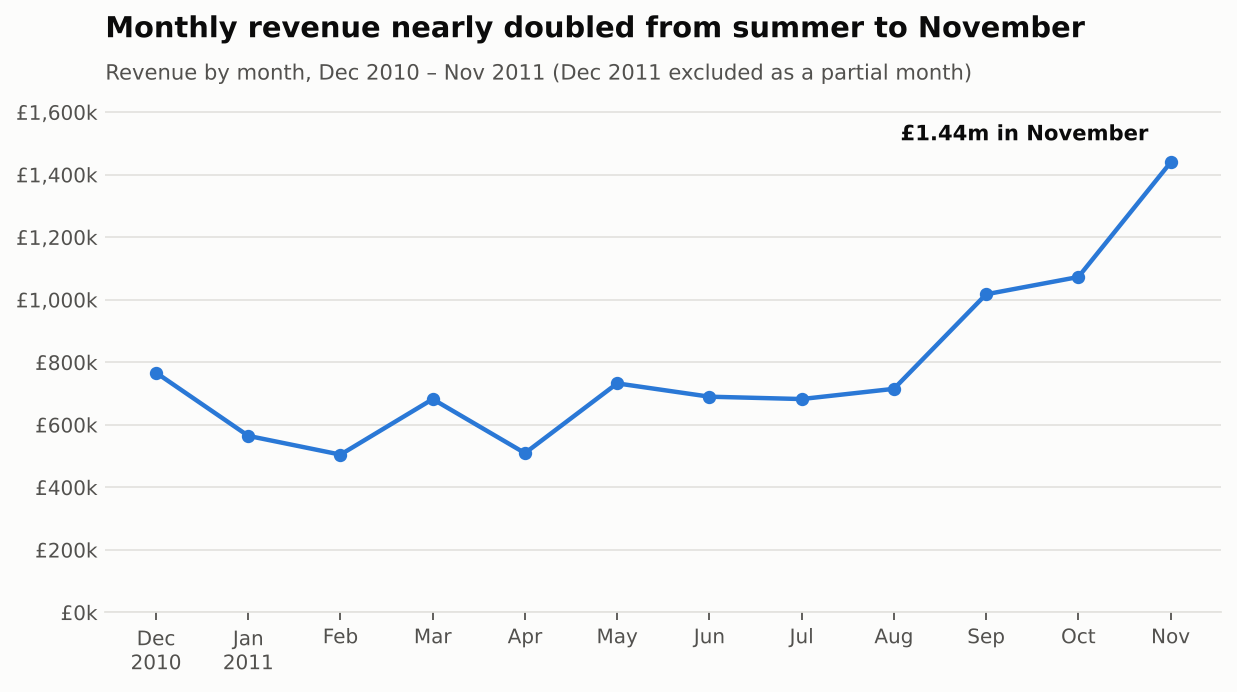

In [7]:
display(Image(charts.monthly_revenue_chart(monthly, "../outputs/charts")))

Revenue was flat at about £0.5–0.75m a month until August, then rose to **£1.44m in November**, which points to strong Q4 / Christmas seasonality. Stock and staffing should be planned for it from September.

## 4. Markets and products

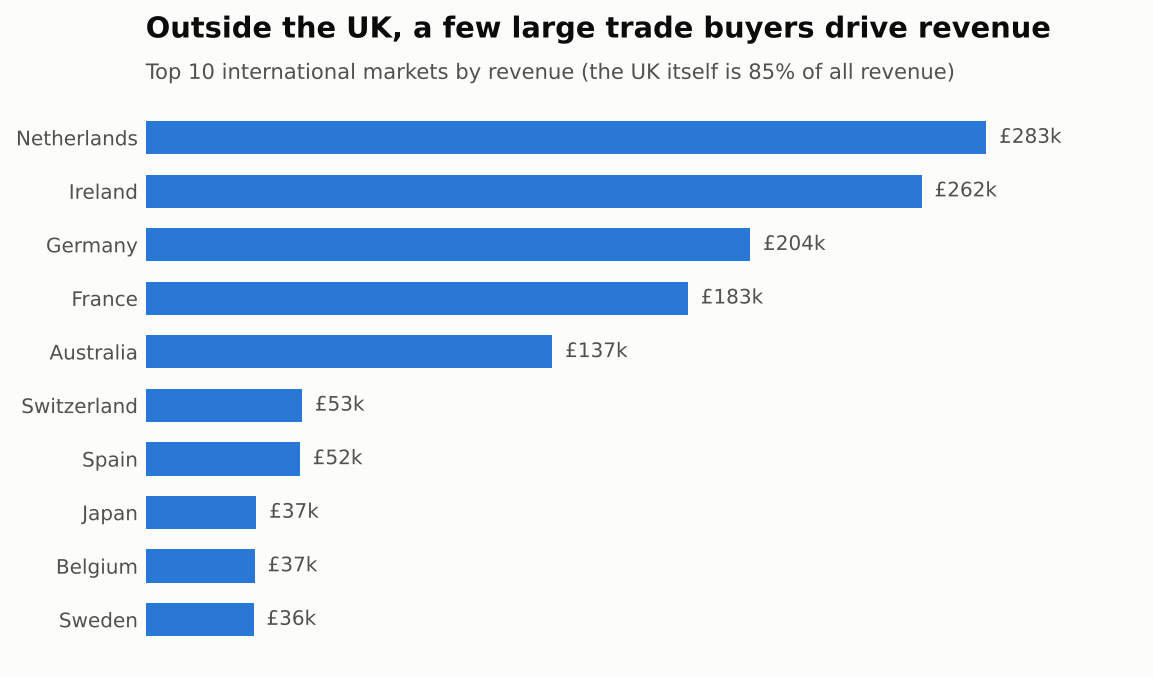

,revenue,orders,customers,avg_order_value
Country,,,,
Netherlands,"283,443.54",93,9,"3,047.78"
Ireland,"261,662.56",279,3,937.86
Germany,"203,849.48",443,94,460.16
France,"182,834.59",380,87,481.14
Australia,"137,124.05",53,9,"2,587.25"
Switzerland,"52,712.50",48,21,"1,098.18"
Spain,"52,029.97",87,29,598.05
Japan,"37,314.37",19,8,"1,963.91"
Belgium,"36,813.69",98,25,375.65


In [8]:
countries = a.revenue_by_country(sales)
display(Image(charts.countries_chart(countries, k["uk_revenue_share"], "../outputs/charts")))
countries

The UK makes up about **85% of revenue**. Abroad, the Netherlands and Australia have very few customers but **average orders of £2,500–3,000**, which suggests wholesale buyers who are worth looking after individually.

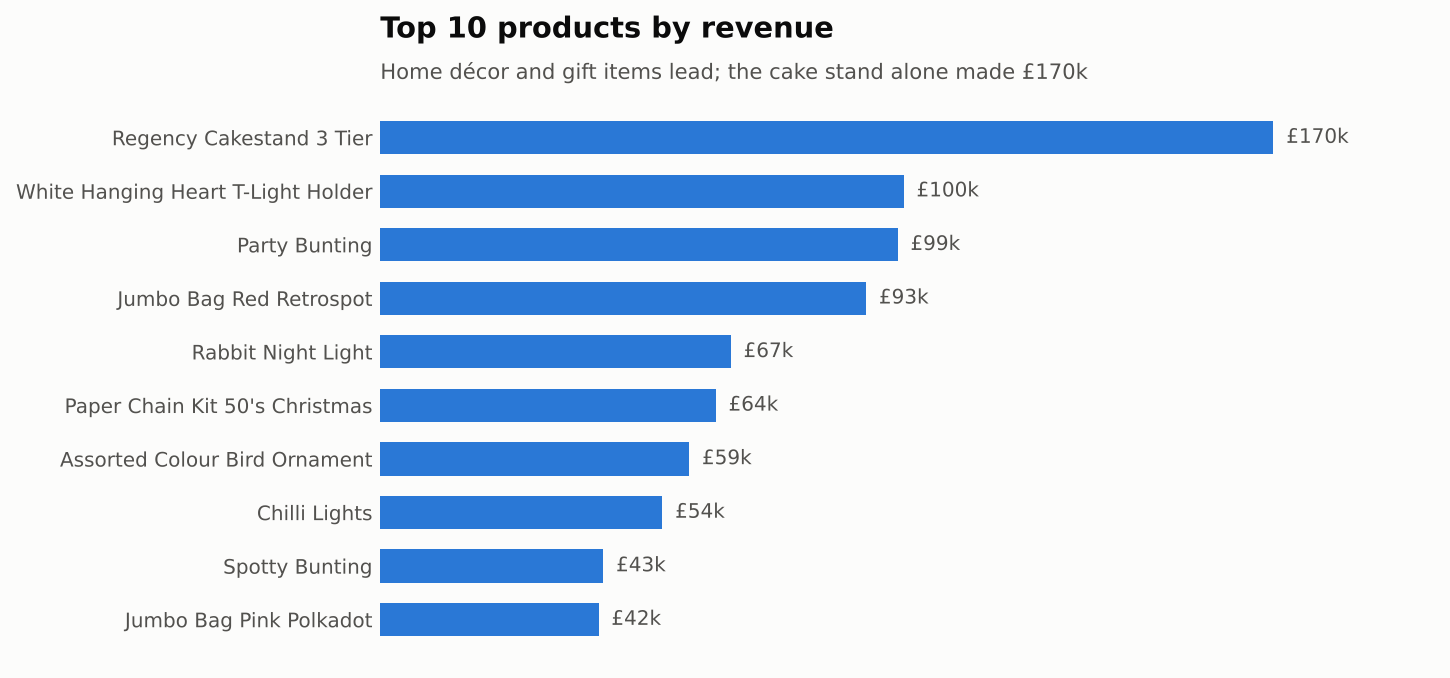

In [9]:
products = a.top_products(sales)
display(Image(charts.products_chart(products, "../outputs/charts")))

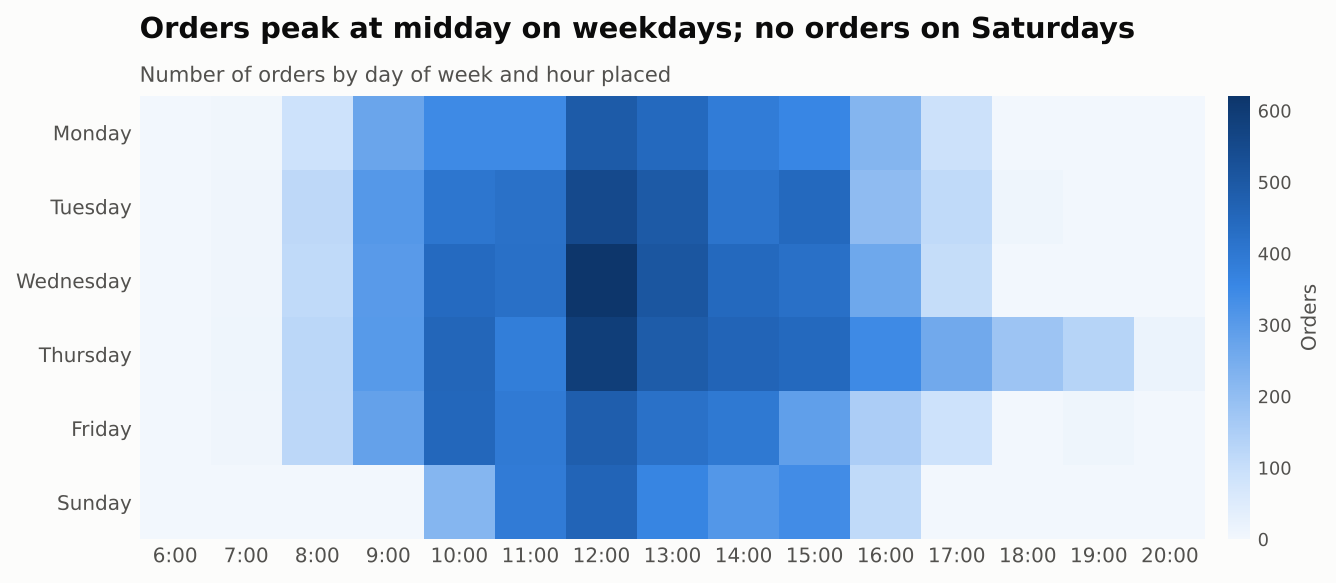

In [10]:
display(Image(charts.heatmap_weekday_hour(a.orders_by_weekday_hour(sales), "../outputs/charts")))

Orders peak between **10:00 and 15:00 on weekdays**, and there are **no Saturday orders**. That fits a business-to-business buying pattern and is the best window for email campaigns.

## 5. Customer segmentation (RFM)
Each customer is scored 1–5 on **Recency**, **Frequency** and **Monetary** value, then grouped into segments a marketing team can act on.

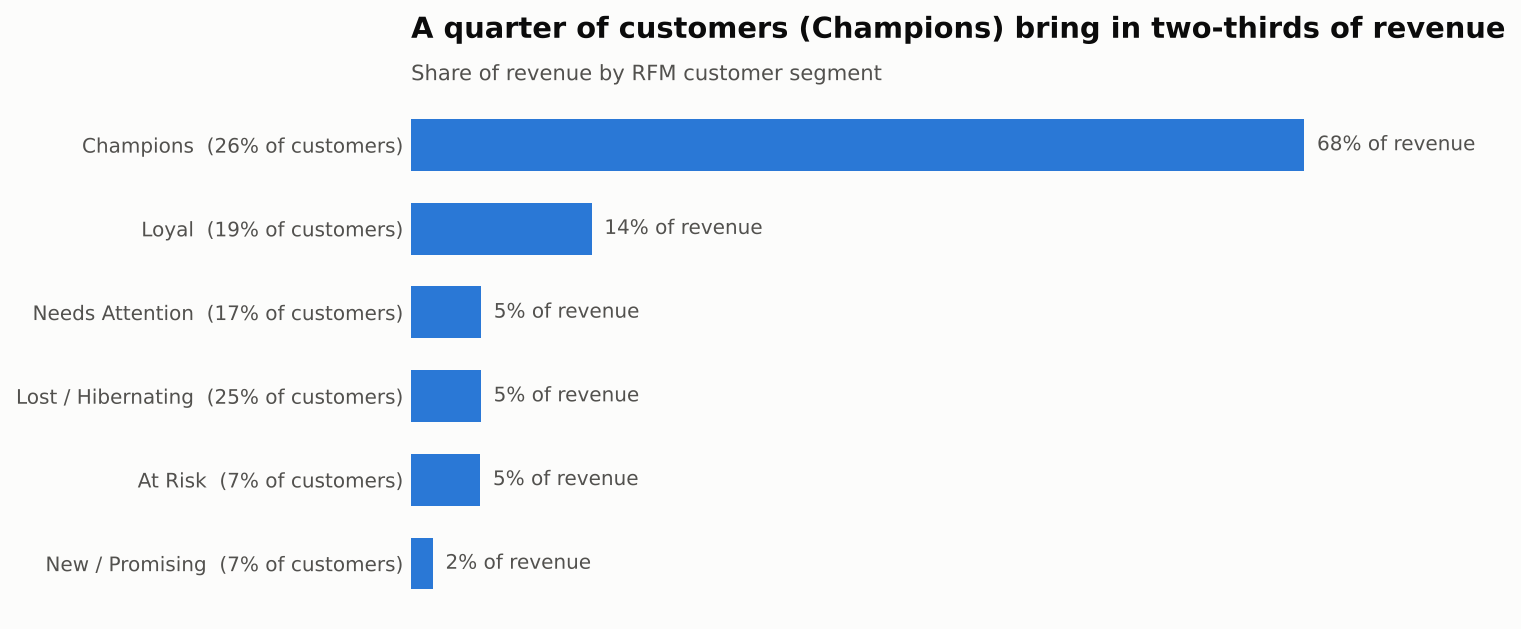

,customers,revenue,avg_recency_days,avg_orders,customer_share,revenue_share
segment,,,,,,
Champions,1116,"5,693,295.05",13.03,9.95,0.26,0.68
Loyal,824,"1,150,386.42",37.21,3.64,0.19,0.14
Needs Attention,715,"446,028.35",109.18,1.73,0.17,0.05
Lost / Hibernating,1076,"444,889.26",217.49,1.10,0.25,0.05
At Risk,285,"440,691.03",135.14,4.82,0.07,0.05
New / Promising,308,"138,177.58",18.13,1.24,0.07,0.02


In [11]:
rfm = a.rfm(customers)
segments = a.segment_summary(rfm)
display(Image(charts.segments_chart(segments, "../outputs/charts")))
segments

**Champions are 26% of customers but bring in 68% of revenue.** The **At Risk** group (frequent buyers who've gone quiet) is the best target for a win-back campaign.

## 6. Cohort retention

Average share of a cohort that returns the next month: 21%


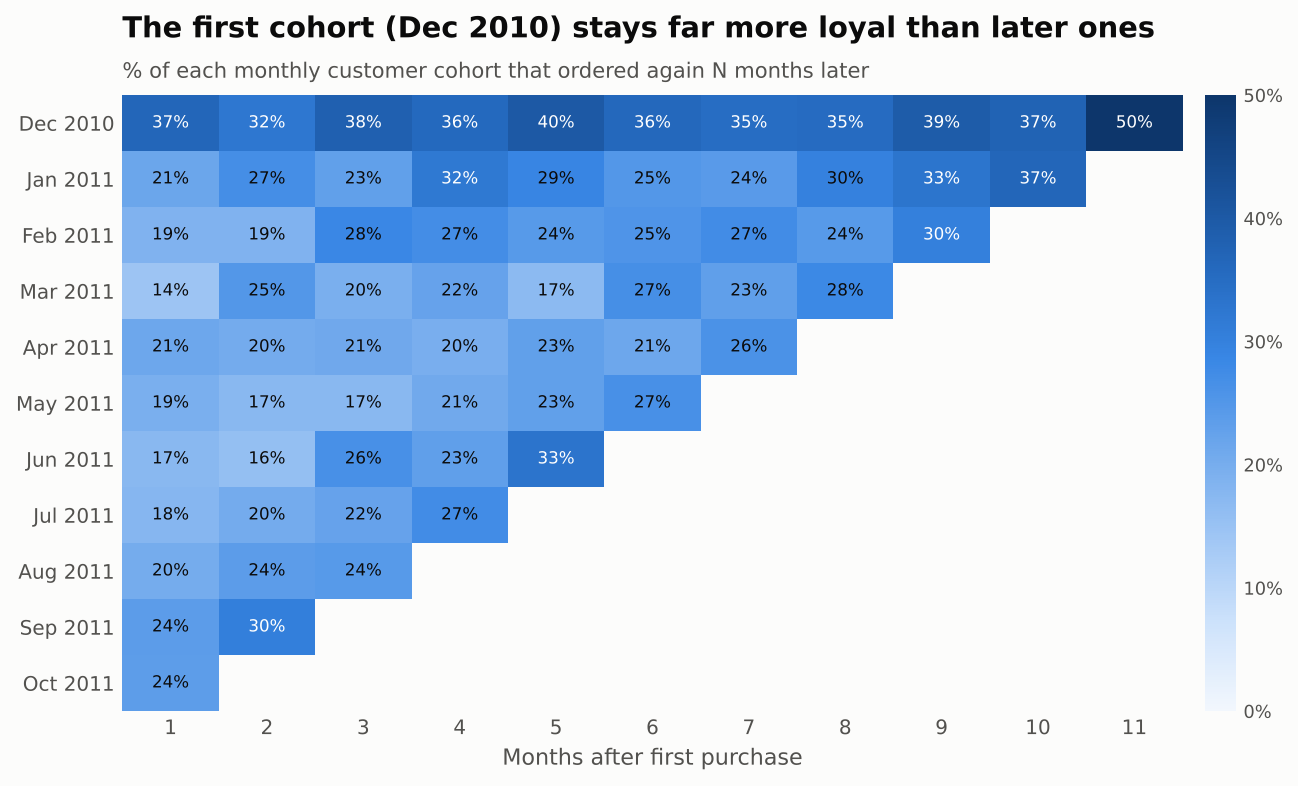

In [12]:
retention = a.cohort_retention(customers)
display(Image(charts.cohort_chart(retention, "../outputs/charts")))
print(f"Average share of a cohort that returns the next month: {retention[1].mean():.0%}")

Only about **1 in 5** new customers order again the next month. The first cohort (Dec 2010, likely long-standing trade customers) stays at **32–50%**. Improving early repeat purchases is the biggest retention opportunity.

## 7. SQL cross-checks
The same data is loaded into SQLite and analysed with the queries in `sql/queries.sql`.

In [13]:
sql = run_all(sales)
sql["repeat_vs_one_off_customers"]

,customer_type,customers,revenue,pct_of_revenue
0,One-off,1502,"540,870.00",6.50
1,Repeat,2822,"7,772,597.00",93.50


In [14]:
sql["products_bought_together"].head(5)

,product_a,product_b,invoices_together
0,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,817
1,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,760
2,JUMBO BAG RED RETROSPOT,JUMBO STORAGE BAG SUKI,718
3,JUMBO BAG RED RETROSPOT,JUMBO SHOPPER VINTAGE RED PAISLEY,676
4,LUNCH BAG RED RETROSPOT,LUNCH BAG SUKI DESIGN,652


## 8. Recommendations
1. **Plan for Q4.** Revenue in Sep–Nov is about 1.8× the average for Dec–Aug, so stock and staffing should increase from August.
2. **Protect the Champions.** 26% of customers bring in 68% of revenue, so offer account management, early access and loyalty pricing.
3. **Win back "At Risk" customers** with targeted offers before they lapse.
4. **Fix early retention.** Only ~21% of new customers return the next month, so a follow-up email series after the first order could help.
5. **Bundle products bought together**, such as matching Jumbo Bags and Regency teacups, to raise average order value.
6. **Grow international trade accounts.** A handful of large wholesale buyers abroad already spend £2,500+ per order.